# Make Noise and Band for decompotition
## EEG Synthetic Contamination Pipeline — Paper-Faithful Protocol

Generates contaminated EEG following the **EEGDenoiseNet** paper methodology.

### Contamination Formula

$$X_{\\text{contaminated}} = X_{\\text{EEG}} + \\alpha \\cdot X_{\\text{artifact}}$$

### Alpha Scaling (SNR-controlled)

$$\\alpha_i = \\sqrt{\\frac{P_{\\text{EEG},i}}{P_{\\text{artifact},i} \\cdot 10^{\\text{SNR}_{\\text{dB}}/10}}}$$

Alpha dihitung **per epoch pair** agar setiap epoch mencapai target SNR secara independen.


### Output Structure
```
processed/
├── eog/
│   ├── clean_eeg_all_epochs.npy         
│   └── linear_synthetic.npy            
├── emg/
│   ├── clean_eeg_all_epochs.npy          
│   └── linear_synthetic.npy            

```


## Cell 1 — Imports

In [1]:
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy import signal as scipy_signal

warnings.filterwarnings('ignore')
print('✅ Libraries loaded successfully.')

✅ Libraries loaded successfully.


## Cell 2 — Configuration

In [2]:
from pathlib import Path
import numpy as np

# ── Reproducibility ──────────────────────────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ── Paths ───────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path(".").resolve()           
PROJECT_DIR  = NOTEBOOK_DIR.parent if (NOTEBOOK_DIR / "eegdenoisenet").is_dir() is False and (NOTEBOOK_DIR.parent / "eegdenoisenet").is_dir() else NOTEBOOK_DIR

# Prioritaskan path lokal eegdenoisenet, fallback ke Kaggle jika dijalankan di cloud
candidate_data_dirs = [
    PROJECT_DIR / "eegdenoisenet",
    NOTEBOOK_DIR / "eegdenoisenet",
    Path("D:/Tsaqib/eegdenoisenet"),
    Path('/kaggle/input/datasets/akipss/eegdenoisenet'),
    Path('/kaggle/input/eegdenoisenet'),
]
DATA_DIR = next((p for p in candidate_data_dirs if (p / "EEG_all_epochs.npy").exists()), PROJECT_DIR / "eegdenoisenet")

OUTPUT_DIR = NOTEBOOK_DIR / "processed"         # /kaggle/working/processed

EOG_DIR = OUTPUT_DIR / "eog"  
EMG_DIR = OUTPUT_DIR / "emg"   


# Membuat folder output secara otomatis jika belum ada
for d in [EOG_DIR, EMG_DIR, ]:
    d.mkdir(parents=True, exist_ok=True)

# ── SNR levels ───────────────────────────────────────────────────────────────
SNR_LEVELS = [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2]

# ── Dual epoch-length targets ────────────────────────────────────────────────
EOG_EPOCH_LEN = None  
EMG_EPOCH_LEN = None  

# ── Print Verification ───────────────────────────────────────────────────────
print(f"Notebook dir   : {NOTEBOOK_DIR}")
print(f"Data dir       : {DATA_DIR}")
print(f"Output dir     : {OUTPUT_DIR}")
print(f"EOG dir        : {EOG_DIR}")
print(f"EMG dir        : {EMG_DIR}")
print(f"SNR levels     : {SNR_LEVELS}")
print(f"EMG_EPOCH_LEN  : {EMG_EPOCH_LEN}")
print(f"Random seed    : {RANDOM_SEED}")

Notebook dir   : /kaggle/working
Data dir       : /kaggle/input/datasets/akipss/eegdenoisenet
Output dir     : /kaggle/working/processed
EOG dir        : /kaggle/working/processed/eog
EMG dir        : /kaggle/working/processed/emg
SNR levels     : [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2]
EMG_EPOCH_LEN  : None
Random seed    : 42


## Cell 3 — Load Raw Data 

In [3]:
EEG = np.load(DATA_DIR / "EEG_all_epochs.npy")
EOG = np.load(DATA_DIR / "EOG_all_epochs.npy")  
EMG = np.load(DATA_DIR / "EMG_all_epochs.npy")  

L_EEG, L_EOG  = EEG.shape[1], EOG.shape[1] 
L_EEG, L_EMG  = EEG.shape[1], EMG.shape[1] 
# L_EEG, L_EOG, L_EMG = EEG.shape[1], EOG.shape[1], L_EMG.shape[1]

print("=" * 65)
print(f"  EEG      : {EEG.shape}  dtype={EEG.dtype}  epoch_len={L_EEG} ")
print(f"  EOG      : {EOG.shape}  dtype={EOG.dtype}  epoch_len={L_EOG} ")
print(f"  EMG      : {EMG.shape}  dtype={EMG.dtype}  epoch_len={L_EMG} ")
print("=" * 65)

# ── EOG pipeline: native epoch length (follows EEG) ──────────────────────────
EOG_EPOCH_LEN = L_EEG   
assert L_EOG == EOG_EPOCH_LEN, f"EOG epoch length ({L_EOG}) != EEG ({EOG_EPOCH_LEN}). Check raw data!"
print(f"\n✅ EOG pipeline — epoch length: {EOG_EPOCH_LEN} pts (native, no resampling)")

assert L_EEG == L_EMG, (
    f"EEG_512 epoch length ({L_EEG}) != EMG_512 epoch length ({L_EMG}). Check raw data!"
)
EMG_EPOCH_LEN = L_EEG   

print(f"\n✅ EMG pipeline — epoch length: {EMG_EPOCH_LEN} pts (native 512 Hz, no resampling)")


  EEG      : (4514, 512)  dtype=float64  epoch_len=512 
  EOG      : (3400, 512)  dtype=float64  epoch_len=512 
  EMG      : (5598, 512)  dtype=float64  epoch_len=[[ 2.02459667e+04  1.49223424e+04  2.19169865e+04 ...  5.43097956e+04
  -3.23854965e+04 -1.29715131e+04]
 [ 2.35956426e+04  2.34999715e+04 -4.77641246e+04 ...  7.73718933e+03
  -5.71058111e+03  1.61080642e+04]
 [ 3.49917675e+04  2.97259977e+04  5.63102495e+03 ...  2.24502893e+04
   4.11809751e+04 -2.12431131e+04]
 ...
 [ 1.49061150e+03  2.17664013e+03  2.19417445e+03 ... -1.44542495e+03
   1.58349897e+03  2.24296355e+03]
 [-3.87053850e+01  1.42655207e+03  2.62229730e+02 ...  3.06593834e+03
   7.84908790e+03  6.01368511e+03]
 [ 1.26054204e+03  1.70741045e+03 -1.15488264e+03 ... -1.03530199e+03
  -2.23368180e+03 -5.99973644e+02]]   

✅ EOG pipeline — epoch length: 512 pts (native, no resampling)

✅ EMG pipeline — epoch length: 512 pts (native 512 Hz, no resampling)


## Cell 4 — Zero-score

In [4]:
def z_score(X: np.ndarray, name: str) -> np.ndarray:
    """Standardize each epoch to zero mean and unit standard deviation."""
    mu_before  = np.mean(X, axis=1)          # (N,) — mean tiap epoch
    std_before = np.std(X, axis=1)           # (N,) — std tiap epoch

    # Hindari pembagian dengan nol
    std_safe = np.where(std_before == 0, 1.0, std_before)

    X_z = (X - mu_before[:, np.newaxis]) / std_safe[:, np.newaxis]

    mu_after  = np.mean(X_z, axis=1)
    std_after = np.std(X_z, axis=1)

    print(f"  {name:<12s} — shape={X.shape}")
    print(f"      epoch[0]      : "
          f"mean_before={mu_before[0]:.4g}   "
          f"std_before={std_before[0]:.4g}")
    print(f"      epoch[0] after: "
          f"mean_after={mu_after[0]:.2e}   "
          f"std_after={std_after[0]:.2f}")

    print(f"      mean_before   : [{mu_before.min():.4g}, {mu_before.max():.4g}]")
    print(f"      std_before    : [{std_before.min():.4g}, {std_before.max():.4g}]")
    print(f"      mean_after    : [{mu_after.min():.2e}, {mu_after.max():.2e}]")
    print(f"      std_after     : [{std_after.min():.2f}, {std_after.max():.2f}]  ✓")

    return X_z


print("Z-score standardization (per epoch) ...")
print(f"{'─'*70}")

# EOG pipeline signals (native 256 Hz)
EEG_c = z_score(EEG, "EEG")
EOG_c = z_score(EOG, "EOG")

# EMG pipeline signals (native 512 Hz)
EMG_c = z_score(EMG, "EMG")

print(f"{'─'*70}")
print("\n✅ Z-score standardization complete.")
print(f"   EOG pipeline → EEG_c {EEG_c.shape}, EOG_c {EOG_c.shape}")
print(f"   EMG pipeline → EEG_c {EEG_c.shape}, EMG_c {EMG_c.shape}")

Z-score standardization (per epoch) ...
──────────────────────────────────────────────────────────────────────
  EEG          — shape=(4514, 512)
      epoch[0]      : mean_before=-7.015   std_before=185.6
      epoch[0] after: mean_after=-4.55e-17   std_after=1.00
      mean_before   : [-47.17, 68.51]
      std_before    : [63.23, 502.8]
      mean_after    : [-2.61e-16, 3.52e-16]
      std_after     : [1.00, 1.00]  ✓
  EOG          — shape=(3400, 512)
      epoch[0]      : mean_before=1.355   std_before=39.59
      epoch[0] after: mean_after=-1.39e-16   std_after=1.00
      mean_before   : [-609.2, 345.4]
      std_before    : [18.84, 537.5]
      mean_after    : [-1.58e-15, 1.49e-15]
      std_after     : [1.00, 1.00]  ✓
  EMG          — shape=(5598, 512)
      epoch[0]      : mean_before=-748.4   std_before=3.396e+04
      epoch[0] after: mean_after=-6.40e-18   std_after=1.00
      mean_before   : [-3.32e+04, 2.073e+04]
      std_before    : [564.1, 3.51e+05]
      mean_after    : 

## Cell 5 — Core Functions

In [5]:
def calculate_snr(eeg_epochs: np.ndarray, noisy_epochs: np.ndarray) -> np.ndarray:
    """
    Compute per-epoch SNR (dB) between clean EEG and contaminated EEG.

    SNR_i = 10 * log10( P_eeg_i / P_noise_i )
    where P_noise_i = mean((noisy_i - eeg_i)^2)
    """
    noise   = noisy_epochs - eeg_epochs          # (N, L)
    P_eeg   = np.mean(eeg_epochs ** 2, axis=1)   # (N,)
    P_noise = np.mean(noise      ** 2, axis=1)   # (N,)

    valid  = (P_eeg > 0) & (P_noise > 0)
    snr_db = np.full(len(eeg_epochs), np.nan)
    snr_db[valid] = 10.0 * np.log10(P_eeg[valid] / P_noise[valid])
    return snr_db

def compute_alpha(eeg_epochs: np.ndarray,
                  artifact_epochs: np.ndarray,
                  snr_db: float) -> np.ndarray:
    """
    Per-epoch alpha scaling factor (paper formula).
        alpha_i = sqrt( P_eeg_i / (P_artifact_i * 10^(SNR/10)) )
    """
    P_eeg = np.mean(eeg_epochs      ** 2, axis=1, keepdims=True)   # (N, 1)
    P_art = np.mean(artifact_epochs ** 2, axis=1, keepdims=True)   # (N, 1)

    snr_linear = 10.0 ** (snr_db / 10.0)

    with np.errstate(divide='ignore', invalid='ignore'):
        alpha = np.where(
            P_art > 0,
            np.sqrt(P_eeg / (P_art * snr_linear)),
            0.0
        )
    return alpha   # (N, 1)


def contaminate_signal(eeg_epochs: np.ndarray,
                       artifact_epochs: np.ndarray,
                       snr_db: float) -> np.ndarray:
    """X_contaminated = X_EEG + alpha * X_artifact"""
    alpha        = compute_alpha(eeg_epochs, artifact_epochs, snr_db)   # (N, 1)
    contaminated = eeg_epochs + alpha * artifact_epochs
    return contaminated.astype(np.float32)


def generate_dataset(eeg: np.ndarray,
                     artifact: np.ndarray,
                     snr_levels: list,
                     label: str,
                     rng: np.random.RandomState) -> tuple:
    """
    Build contaminated EEG for every SNR level with random pairing.
    n = min(N_eeg, N_artifact) epochs are used.
    """
    n = min(len(eeg), len(artifact))

    art_indices = rng.permutation(len(artifact))[:n]
    eeg_paired  = eeg[:n]
    art_paired  = artifact[art_indices]

    print(f"\n{'─'*70}")
    print(f" {label} contamination  |  pairs: {n}  |  "
          f"EEG epochs 0–{n-1}  |  artifact indices shuffled")
    print(f"{'─'*70}")
    print(f"  {'SNR target':>12} | {'SNR actual':>10} | "
          f"{'corr(clean,noisy)':>18} | shape")
    print(f"  {'─'*12}-+-{'─'*10}-+-{'─'*18}-+-{'─'*20}")

    synthetic = {}
    for snr in snr_levels:
        noisy = contaminate_signal(eeg_paired, art_paired, snr)

        actual_snrs = calculate_snr(eeg_paired.astype(np.float32), noisy)
        mean_actual = np.nanmean(actual_snrs)

        corrs = np.array([
            np.corrcoef(eeg_paired[i], noisy[i])[0, 1]
            for i in range(min(n, 50))
        ])
        mean_corr = np.nanmean(corrs)

        synthetic[snr] = noisy
        print(f"  {snr:>+12d} | {mean_actual:>+9.3f} | {mean_corr:>18.4f} | {noisy.shape}")

    print(f"{'─'*70}")
    return synthetic, eeg_paired.astype(np.float32), art_paired.astype(np.float32)


def save_outputs(out_dir: Path,
                 clean_arr: np.ndarray,
                 synthetic: dict) -> None:
    """Save clean EEG and synthetic dict to *out_dir*."""
    out_dir.mkdir(parents=True, exist_ok=True)

    clean_path = out_dir / "clean_eeg_all_epochs.npy"
    np.save(clean_path, clean_arr)

    obj = np.empty((), dtype=object)
    obj[()] = synthetic
    syn_path = out_dir / "linear_synthetic.npy"
    np.save(syn_path, obj)

    print(f"  Saved: {clean_path}  shape={clean_arr.shape}  dtype={clean_arr.dtype}")
    print(f"  Saved: {syn_path}  keys={sorted(synthetic.keys())}")


def validate_dataset(label: str,
                     clean_arr: np.ndarray,
                     synthetic: dict,
                     out_dir: Path) -> pd.DataFrame:
    """Print and return a validation table for one pipeline."""
    print(f"\n{'═'*72}")
    print(f"  VALIDATION — {label} Pipeline")
    print(f"{'═'*72}")

    print("\n  clean_eeg_all_epochs.npy")
    print(f"    shape : {clean_arr.shape}")
    print(f"    dtype : {clean_arr.dtype}")
    print(f"    min   : {clean_arr.min():.6g}")
    print(f"    max   : {clean_arr.max():.6g}")
    print(f"    mean  : {clean_arr.mean():.6e}")
    print(f"    std   : {clean_arr.std():.6g}")

    rows = []
    print(f"\n  {'SNR target':>12} | {'SNR actual':>10} | {'Δ SNR':>7} | "
          f"{'corr':>6} | {'min':>9} | {'max':>9} | {'mean':>9} | {'std':>9}")
    print(f"  {'─'*95}")

    for snr, arr in sorted(synthetic.items()):
        actual_snrs  = calculate_snr(clean_arr, arr)
        mean_actual  = float(np.nanmean(actual_snrs))
        delta        = mean_actual - snr
        corrs = np.array([
            np.corrcoef(clean_arr[i], arr[i])[0, 1]
            for i in range(min(len(clean_arr), 50))
        ])
        mean_corr = float(np.nanmean(corrs))

        print(f"  {snr:>+12d} | {mean_actual:>+10.3f} | {delta:>+7.3f} | "
              f"{mean_corr:>6.4f} | {arr.min():>9.4g} | {arr.max():>9.4g} | "
              f"{arr.mean():>9.3e} | {arr.std():>9.4g}")

        rows.append(dict(pipeline=label, snr_target=snr,
                         snr_actual=mean_actual, delta=delta,
                         corr=mean_corr, shape=arr.shape,
                         dtype=str(arr.dtype),
                         vmin=arr.min(), vmax=arr.max(),
                         vmean=arr.mean(), vstd=arr.std()))

    # Reload integrity check
    clean_r = np.load(out_dir / "clean_eeg_all_epochs.npy")
    syn_r   = np.load(out_dir / "linear_synthetic.npy", allow_pickle=True).item()
    assert clean_r.shape == clean_arr.shape,   "Reload shape mismatch: clean"
    assert isinstance(syn_r, dict),            "Reload type error: not a dict"
    assert sorted(syn_r.keys()) == sorted(SNR_LEVELS), "Reload key mismatch"
    assert syn_r[SNR_LEVELS[0]].shape == clean_arr.shape, "Reload shape mismatch: synthetic"

    print(f"\n  ✅ Reload integrity check passed.")
    print(f"{'═'*72}")
    return pd.DataFrame(rows)


print("✅ All functions defined.")

✅ All functions defined.


## Cell 6 — Generate EOG Contamination

In [6]:
rng_eog = np.random.RandomState(RANDOM_SEED)

synthetic_eog, clean_eog_arr, art_eog_arr = generate_dataset(
    eeg       = EEG_c,
    artifact  = EOG_c,
    snr_levels= SNR_LEVELS,
    label     = "EOG",
    rng       = rng_eog,
)


──────────────────────────────────────────────────────────────────────
 EOG contamination  |  pairs: 3400  |  EEG epochs 0–3399  |  artifact indices shuffled
──────────────────────────────────────────────────────────────────────
    SNR target | SNR actual |  corr(clean,noisy) | shape
  ────────────-+-──────────-+-──────────────────-+-────────────────────
            -7 |    -7.000 |             0.3844 | (3400, 512)
            -6 |    -6.000 |             0.4259 | (3400, 512)
            -5 |    -5.000 |             0.4695 | (3400, 512)
            -4 |    -4.000 |             0.5147 | (3400, 512)
            -3 |    -3.000 |             0.5609 | (3400, 512)
            -2 |    -2.000 |             0.6072 | (3400, 512)
            -1 |    -1.000 |             0.6527 | (3400, 512)
            +0 |    +0.000 |             0.6966 | (3400, 512)
            +1 |    +1.000 |             0.7381 | (3400, 512)
            +2 |    +2.000 |             0.7764 | (3400, 512)
─────────────────────

## Cell 7 — Generate EMG Contamination

> ** EMG pipeline menggunakan `EEG_c_512` (EEG native 512 Hz)
> sebagai sinyal EEG bersih, bukan `EEG_c` (native 256 Hz, dipakai pipeline EOG).
> `EMG_c` berasal dari `EMG_512` (native 512 Hz) yang sudah di-zero-center di Cell 4.
> Output: `clean_emg_arr` dan `synthetic_emg` mengikuti epoch length data 512Hz asli.


In [7]:
rng_emg = np.random.RandomState(RANDOM_SEED)

synthetic_emg, clean_emg_arr, art_emg_arr = generate_dataset(
    eeg       = EEG_c,   
    artifact  = EMG_c,       
    snr_levels= SNR_LEVELS,
    label     = "EMG",
    rng       = rng_emg,
)



──────────────────────────────────────────────────────────────────────
 EMG contamination  |  pairs: 4514  |  EEG epochs 0–4513  |  artifact indices shuffled
──────────────────────────────────────────────────────────────────────
    SNR target | SNR actual |  corr(clean,noisy) | shape
  ────────────-+-──────────-+-──────────────────-+-────────────────────
            -7 |    -7.000 |             0.4059 | (4514, 512)
            -6 |    -6.000 |             0.4462 | (4514, 512)
            -5 |    -5.000 |             0.4884 | (4514, 512)
            -4 |    -4.000 |             0.5320 | (4514, 512)
            -3 |    -3.000 |             0.5764 | (4514, 512)
            -2 |    -2.000 |             0.6207 | (4514, 512)
            -1 |    -1.000 |             0.6643 | (4514, 512)
            +0 |    +0.000 |             0.7063 | (4514, 512)
            +1 |    +1.000 |             0.7460 | (4514, 512)
            +2 |    +2.000 |             0.7826 | (4514, 512)
─────────────────────

## Cell 8 — Save Outputs

| Folder | Array | Shape |
|--------|-------|-------|
| `eog/` | `clean_eeg_all_epochs.npy` | (N_pairs, **512**) |
| `eog/` | `linear_synthetic.npy` | dict { snr: (N_pairs, **512**) } |
| `emg/` | `clean_eeg_all_epochs.npy` | (N_pairs, **1024**) |
| `emg/` | `linear_synthetic.npy` | dict { snr: (N_pairs, **1024**) } |


In [8]:
print("Saving EOG pipeline outputs ...")
save_outputs(EOG_DIR, clean_eog_arr, synthetic_eog)

print("\nSaving EMG pipeline outputs ...")
save_outputs(EMG_DIR, clean_emg_arr, synthetic_emg)

print("\n✅ All outputs saved.")

Saving EOG pipeline outputs ...
  Saved: /kaggle/working/processed/eog/clean_eeg_all_epochs.npy  shape=(3400, 512)  dtype=float32
  Saved: /kaggle/working/processed/eog/linear_synthetic.npy  keys=[-7, -6, -5, -4, -3, -2, -1, 0, 1, 2]

Saving EMG pipeline outputs ...
  Saved: /kaggle/working/processed/emg/clean_eeg_all_epochs.npy  shape=(4514, 512)  dtype=float32
  Saved: /kaggle/working/processed/emg/linear_synthetic.npy  keys=[-7, -6, -5, -4, -3, -2, -1, 0, 1, 2]

✅ All outputs saved.


## Cell 9 — Validation

In [9]:
df_eog = validate_dataset("EOG", clean_eog_arr, synthetic_eog, EOG_DIR)
df_emg = validate_dataset("EMG", clean_emg_arr, synthetic_emg, EMG_DIR)

print(f"\n📐 Epoch lengths confirmed:")
print(f"   EOG pipeline — clean_eog_arr: {clean_eog_arr.shape} ")
print(f"   EMG pipeline — clean_emg_arr: {clean_emg_arr.shape} ")



════════════════════════════════════════════════════════════════════════
  VALIDATION — EOG Pipeline
════════════════════════════════════════════════════════════════════════

  clean_eeg_all_epochs.npy
    shape : (3400, 512)
    dtype : float32
    min   : -5.4927
    max   : 5.14105
    mean  : -3.155540e-10
    std   : 1

    SNR target | SNR actual |   Δ SNR |   corr |       min |       max |      mean |       std
  ───────────────────────────────────────────────────────────────────────────────────────────────
            -7 |     -7.000 |  -0.000 | 0.3844 |    -12.47 |     15.65 | -3.494e-10 |      2.45
            -6 |     -6.000 |  -0.000 | 0.4259 |    -11.34 |     14.23 | 1.323e-10 |      2.23
            -5 |     -5.000 |  -0.000 | 0.4695 |    -10.32 |     12.98 | 9.882e-11 |     2.038
            -4 |     -4.000 |  -0.000 | 0.5147 |    -9.418 |     11.85 | -4.012e-10 |     1.872
            -3 |     -3.000 |  +0.000 | 0.5609 |    -8.613 |     10.85 | 8.622e-10 |     1.729
  

## Cell 10 — Visualisation: EOG Contamination

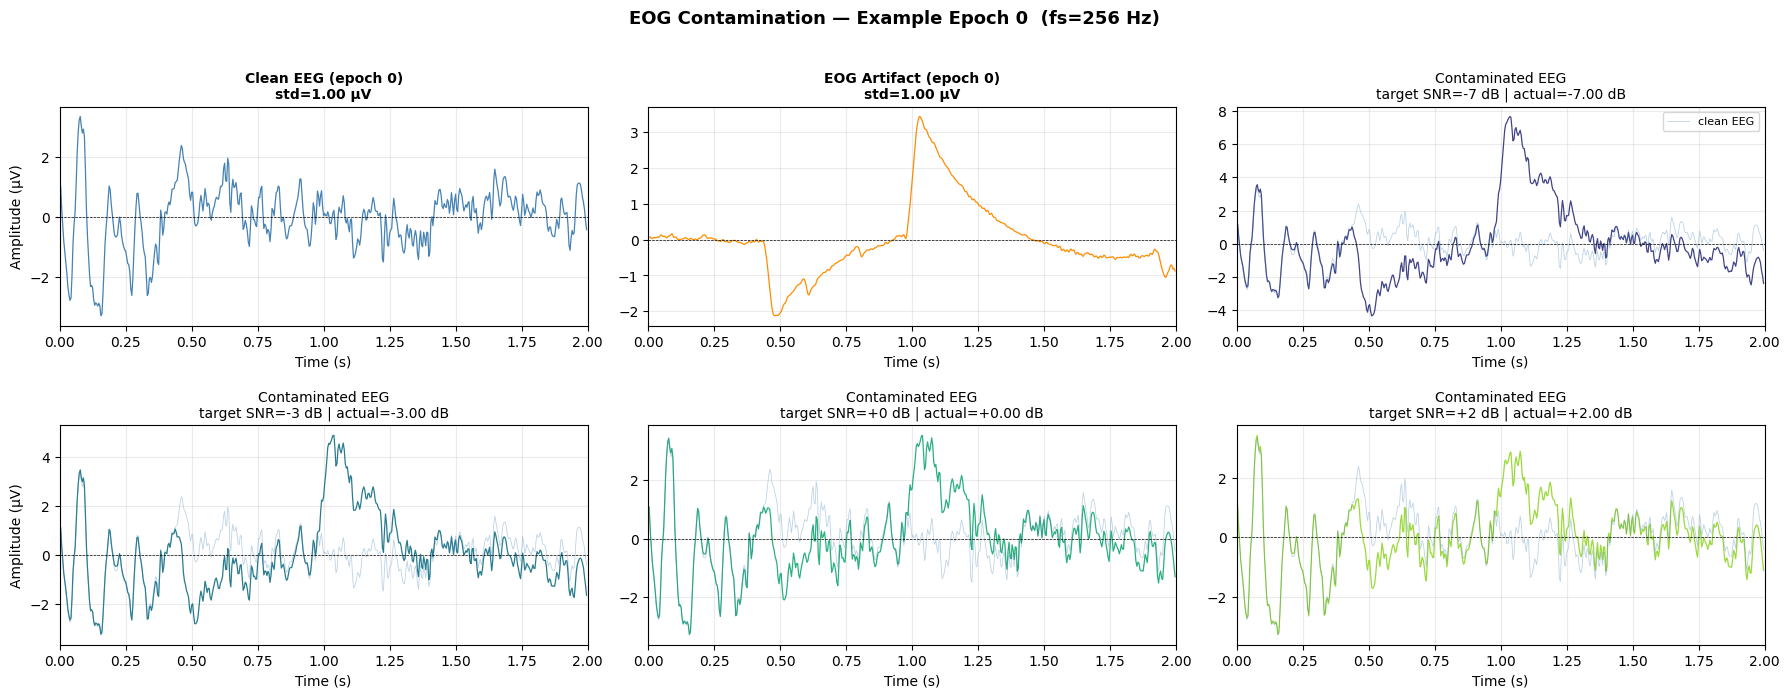

Plot saved: /kaggle/working/processed/contamination_eog_epoch0.png


In [10]:
import math

def plot_contamination(clean_arr, art_arr, synthetic, snr_levels_to_plot,
                       label, epoch_idx=0, fs=256, ncols=3):

    n_snr   = len(snr_levels_to_plot)
    n_total = n_snr + 2
    nrows   = math.ceil(n_total / ncols)

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(6 * ncols, 3.4 * nrows),
                             sharex=False)
    axes = np.atleast_1d(axes).ravel()

    n_samples = clean_arr.shape[1]
    t_end     = n_samples / fs
    time      = np.arange(n_samples) / fs
    eeg_ep    = clean_arr[epoch_idx]
    art_ep    = art_arr[epoch_idx]

    # --- Panel 0: Clean EEG ---
    axes[0].plot(time, eeg_ep, lw=0.9, color='steelblue')
    axes[0].set_title(f"Clean EEG (epoch {epoch_idx})\nstd={eeg_ep.std():.2f} µV",
                      fontsize=10, fontweight='bold')

    # --- Panel 1: Artifact ---
    color_art = 'darkorange' if label == 'EOG' else 'crimson'
    axes[1].plot(time, art_ep, lw=0.9, color=color_art)
    axes[1].set_title(f"{label} Artifact (epoch {epoch_idx})\nstd={art_ep.std():.2f} µV",
                      fontsize=10, fontweight='bold')

    # --- Panel 2..: Contaminated EEG per SNR ---
    cmap = plt.cm.viridis(np.linspace(0.2, 0.85, n_snr))
    for k, snr in enumerate(snr_levels_to_plot):
        noisy_ep = synthetic[snr][epoch_idx]
        ax = axes[k + 2]
        ax.plot(time, noisy_ep, lw=0.9, color=cmap[k])
        ax.plot(time, eeg_ep, lw=0.6, color='steelblue', alpha=0.35, label='clean EEG')
        actual_snr = calculate_snr(clean_arr[[epoch_idx]],
                                   synthetic[snr][[epoch_idx]])[0]
        ax.set_title(f"Contaminated EEG\ntarget SNR={snr:+d} dB | actual={actual_snr + 0.0:+.2f} dB",
                     fontsize=10)
        if k == 0:
            ax.legend(loc='upper right', fontsize=8)

    # --- Styling umum: xlim, xticks, xlabel di SEMUA panel ---
    for i in range(n_total):
        axes[i].grid(True, alpha=0.25)
        axes[i].axhline(0, color='k', lw=0.5, ls='--')
        axes[i].set_xlim(0, t_end)
        axes[i].set_xticks(np.arange(0, t_end + 1e-9, 0.25))
        axes[i].tick_params(axis='x', labelbottom=True)
        axes[i].set_xlabel('Time (s)')
        if i % ncols == 0:                       # ylabel hanya kolom kiri
            axes[i].set_ylabel('Amplitude (µV)')

    # Sembunyikan panel kosong (jika ada)
    for j in range(n_total, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(f"{label} Contamination — Example Epoch {epoch_idx}  (fs={fs:.0f} Hz)",
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout(h_pad=1.5)
    out_path = OUTPUT_DIR / f"contamination_{label.lower()}_epoch{epoch_idx}.png"
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Plot saved: {out_path}")

# FIX: fs=256 explicit — this is the EOG pipeline (native rate 256 Hz, not 512 Hz)
plot_contamination(
    clean_arr          = clean_eog_arr,
    art_arr             = art_eog_arr,
    synthetic           = synthetic_eog,
    snr_levels_to_plot  = [-7, -3, 0, 2],
    label               = "EOG",
    epoch_idx           = 0,
    fs                  = 256,
)


## Cell 11 — Visualisation: EMG Contamination

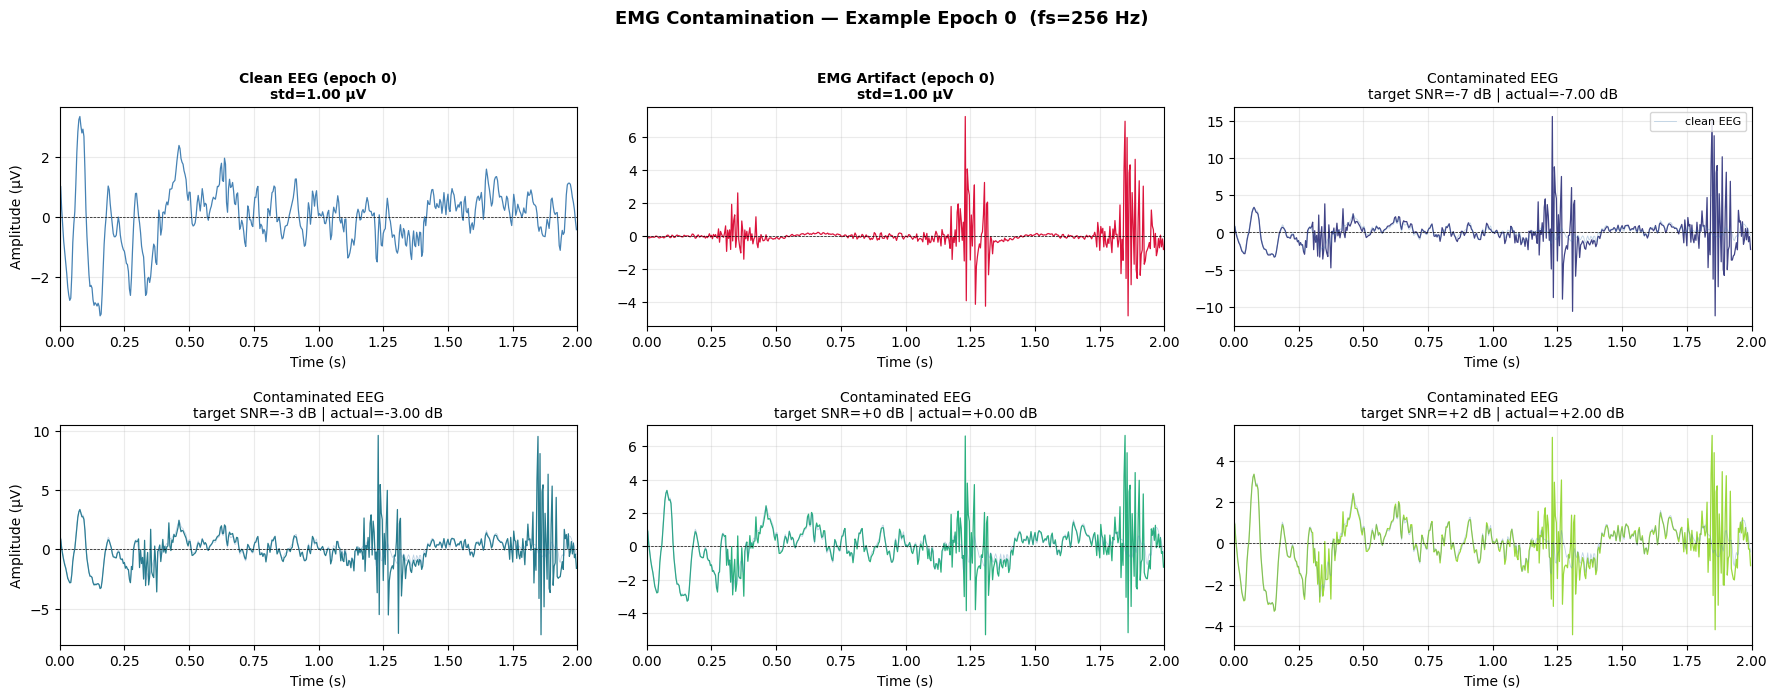

Plot saved: /kaggle/working/processed/contamination_emg_epoch0.png


In [11]:
plot_contamination(
    clean_arr          = clean_emg_arr,
    art_arr            = art_emg_arr,
    synthetic          = synthetic_emg,
    snr_levels_to_plot = [-7, -3, 0, 2],
    label              = "EMG",
    epoch_idx          = 0,
)

## Cell 12 — SNR Accuracy Summary Plot

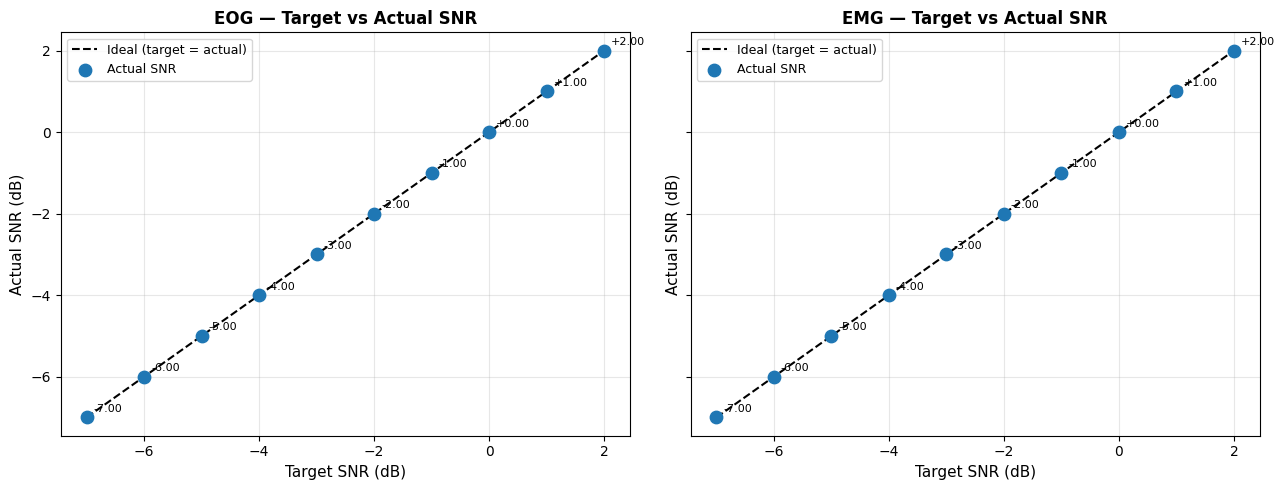

Plot saved: /kaggle/working/processed/snr_accuracy.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, df, label in zip(axes, [df_eog, df_emg], ["EOG", "EMG"]):
    targets = df['snr_target'].values
    actuals = df['snr_actual'].values

    ax.plot(targets, targets, 'k--', lw=1.5, label='Ideal (target = actual)')
    ax.scatter(targets, actuals, s=80, zorder=5, label='Actual SNR')
    for t, a in zip(targets, actuals):
        ax.annotate(f"{a:+.2f}", (t, a), textcoords='offset points',
                    xytext=(5, 4), fontsize=8)

    ax.set_xlabel('Target SNR (dB)', fontsize=11)
    ax.set_ylabel('Actual SNR (dB)', fontsize=11)
    ax.set_title(f'{label} — Target vs Actual SNR', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
snr_plot_path = OUTPUT_DIR / "snr_accuracy.png"
plt.savefig(snr_plot_path, dpi=120, bbox_inches='tight')
plt.show()
print(f"Plot saved: {snr_plot_path}")

## Cell 13 — Final Reload Integrity Check

In [13]:
print("Final reload integrity check ...")
EXPECTED_LEN = {"EOG": EOG_EPOCH_LEN, "EMG": EMG_EPOCH_LEN}

for tag, d, exp_len in [("EOG", EOG_DIR, EOG_EPOCH_LEN), ("EMG", EMG_DIR, EMG_EPOCH_LEN)]:
    clean_r = np.load(d / "clean_eeg_all_epochs.npy")
    syn_r   = np.load(d / "linear_synthetic.npy", allow_pickle=True).item()

    assert clean_r.dtype   == np.float32,              f"{tag} clean dtype wrong"
    assert isinstance(syn_r, dict),                    f"{tag} synthetic not dict"
    assert sorted(syn_r.keys()) == sorted(SNR_LEVELS), f"{tag} key mismatch"
    for snr, arr in syn_r.items():
        assert arr.shape == clean_r.shape, f"{tag} shape mismatch at snr={snr}"
        assert arr.dtype == np.float32,    f"{tag} synthetic dtype wrong at snr={snr}"
    assert clean_r.shape[1] == exp_len, \
        f"{tag} epoch length wrong: got {clean_r.shape[1]}, expected {exp_len}"

print("\n✅ All reload checks passed (EOG, EMG).")


Final reload integrity check ...

✅ All reload checks passed (EOG, EMG).
